# Customer Churn Prediction - End-to-End Machine Learning

**Python · pandas · scikit-learn · EDA · Classification · Model Evaluation**

**Business question:** Which customers are more likely to churn, and which observable characteristics are associated with that risk?

**Data:** IBM Telco Customer Churn sample (7,043 customers, 21 original columns). This is a demonstration dataset, not Helios Towers data.

**Methodology:** inspect → clean → explore → stratified split → leakage-safe preprocessing → compare models → evaluate → interpret → save.

> Run cells in order. Metrics and charts are computed from the dataset; no performance numbers are assumed in advance.

## 0. Setup
If needed in Colab, uncomment the installation cell.

In [1]:
# %pip install -q pandas numpy matplotlib seaborn scikit-learn joblib

In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, RocCurveDisplay,
                             PrecisionRecallDisplay, precision_recall_curve)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
print("pandas:", pd.__version__)

pandas: 2.2.3


## 1. Load the dataset
The notebook first looks for `data/Telco-Customer-Churn.csv`, then tries the public IBM raw CSV URL. If offline, place the file in `data/`.

In [3]:
LOCAL_PATH = Path("data/Telco-Customer-Churn.csv")
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
if LOCAL_PATH.exists():
    df = pd.read_csv(LOCAL_PATH)
else:
    try:
        df = pd.read_csv(DATA_URL)
    except Exception as exc:
        raise RuntimeError("Dataset unavailable. Download the IBM CSV and save it to data/Telco-Customer-Churn.csv") from exc
print("Shape:", df.shape)
display(df.head())

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Data understanding and quality checks

In [4]:
df.info()
display(df.isna().sum().rename("null_count").to_frame())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
display(df["Churn"].value_counts(dropna=False).to_frame("count"))
display((df["Churn"].value_counts(normalize=True) * 100).round(2).to_frame("percent"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,null_count
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Duplicate rows: 0
Duplicate customer IDs: 0


,count
Churn,
No,5174
Yes,1869


,percent
Churn,
No,73.46
Yes,26.54


In [5]:
# Strings consisting of spaces are not always detected by isna().
total_charges_as_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")
invalid_total = total_charges_as_numeric.isna()
print("Unparseable TotalCharges:", invalid_total.sum())
display(df.loc[invalid_total, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])
print("All affected customers have tenure=0:", bool(df.loc[invalid_total, "tenure"].eq(0).all()))

Unparseable TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


All affected customers have tenure=0: True


## 3. Minimal data cleaning (before splitting)

- Convert `TotalCharges` to numeric and preserve an indicator for originally missing values.
- **Do not** fit encoders, scalers, or statistical imputers on the entire dataset.
- We will use a zero fill for `TotalCharges` *only if* all its missing values have `tenure == 0`. This is a documented business assumption, not a verified billing fact.
- `customerID` is an identifier, not a predictive feature.

In [6]:
data = df.copy()
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")
data["TotalCharges_missing"] = data["TotalCharges"].isna().astype(int)
assert data["Churn"].isin(["Yes", "No"]).all(), "Unexpected target label"
assert data["customerID"].is_unique, "Duplicate customer identifiers need investigation"
missing_total = data["TotalCharges"].isna()
assert data.loc[missing_total, "tenure"].eq(0).all(), "Missing TotalCharges not limited to tenure=0; revisit strategy"
data.loc[missing_total, "TotalCharges"] = 0.0
print("Remaining nulls:", data.isna().sum().sum())
print("Shape:", data.shape)
display(data[["tenure", "MonthlyCharges", "TotalCharges"]].describe())

Remaining nulls: 0
Shape: (7043, 22)


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


## 4. Exploratory Data Analysis (EDA)
These plots describe associations, not causal effects.

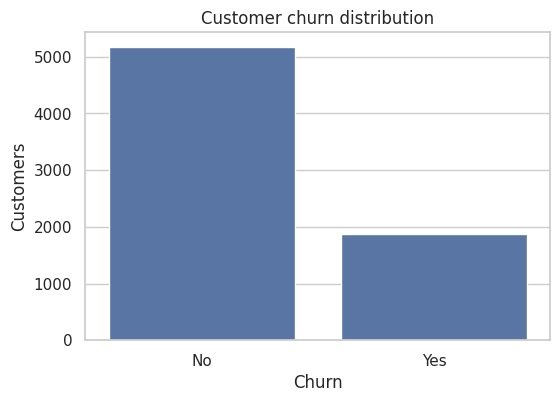

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=data, x="Churn", order=["No", "Yes"], ax=ax)
ax.set(title="Customer churn distribution", xlabel="Churn", ylabel="Customers")
plt.show()

,total_customers,churned_customers,churn_rate_pct
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


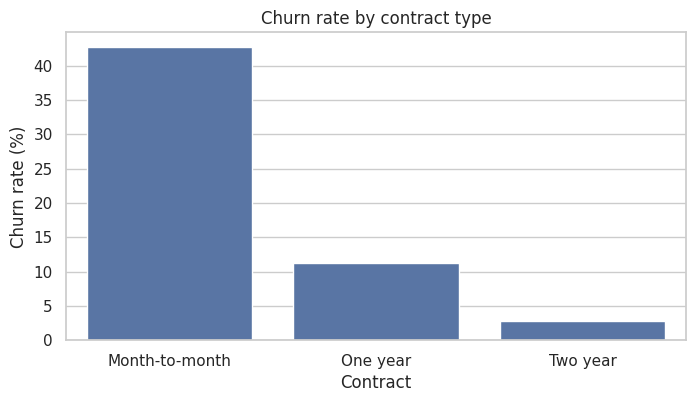

In [8]:
contract_summary = (data.groupby("Contract", observed=True)["Churn"]
                    .agg(total_customers="count", churned_customers=lambda s: s.eq("Yes").sum()))
contract_summary["churn_rate_pct"] = (100 * contract_summary["churned_customers"] / contract_summary["total_customers"])
display(contract_summary.sort_values("churn_rate_pct", ascending=False).round(2))
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=contract_summary.reset_index(), x="Contract", y="churn_rate_pct", ax=ax)
ax.set(title="Churn rate by contract type", ylabel="Churn rate (%)", xlabel="Contract")
plt.show()

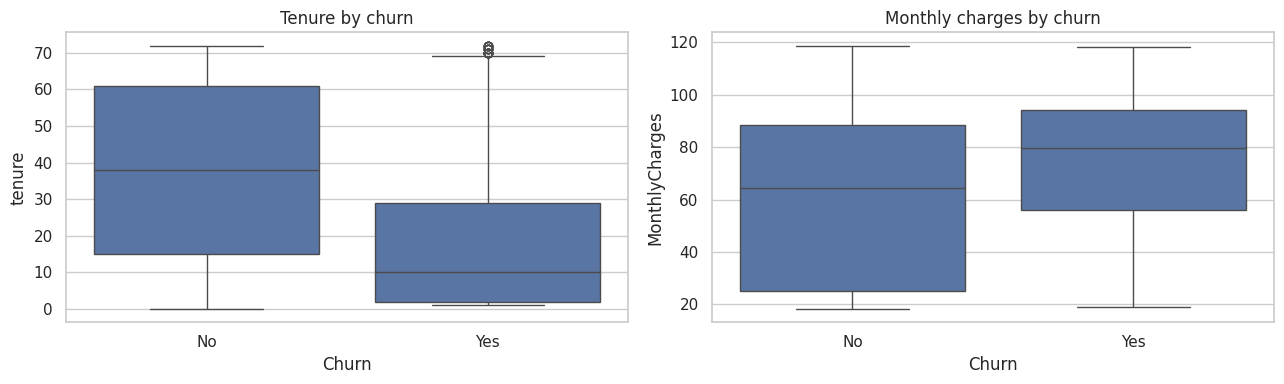

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=data, x="Churn", y="tenure", order=["No", "Yes"], ax=axes[0])
axes[0].set(title="Tenure by churn")
sns.boxplot(data=data, x="Churn", y="MonthlyCharges", order=["No", "Yes"], ax=axes[1])
axes[1].set(title="Monthly charges by churn")
plt.tight_layout()
plt.show()

In [10]:
for feature in ["InternetService", "PaymentMethod", "TechSupport"]:
    rates = (data.groupby(feature, observed=True)["Churn"]
             .apply(lambda s: 100 * s.eq("Yes").mean())
             .sort_values(ascending=False))
    print(f"\n{feature}: churn rate (%)")
    display(rates.round(2).to_frame("churn_rate_pct"))


InternetService: churn rate (%)


,churn_rate_pct
InternetService,
Fiber optic,41.89
DSL,18.96
No,7.40



PaymentMethod: churn rate (%)


,churn_rate_pct
PaymentMethod,
Electronic check,45.29
Mailed check,19.11
Bank transfer (automatic),16.71
Credit card (automatic),15.24



TechSupport: churn rate (%)


,churn_rate_pct
TechSupport,
No,41.64
Yes,15.17
No internet service,7.40


### Exploratory findings

Month-to-month customers have the highest observed churn rate (42.71%), compared with one-year (11.27%) and two-year (2.83%) contracts. Churn is also more frequent among fiber-optic customers (41.89%) than DSL customers (18.96%). These patterns are descriptive associations; they do not establish why customers leave.

Tenure and monthly charges are explored visually above. I treat them as potentially useful predictive features rather than drawing causal conclusions from the charts.

## 5. Define features and create a stratified holdout test set
The test set is reserved for the final evaluation. No preprocessing model is fitted before this split.

In [11]:
X = data.drop(columns=["Churn", "customerID"])
y = data["Churn"].map({"No": 0, "Yes": 1}).astype(int)
assert y.notna().all()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train churn rate:", round(y_train.mean(), 4))
print("Test churn rate:", round(y_test.mean(), 4))

Train: (5634, 20) Test: (1409, 20)
Train churn rate: 0.2654
Test churn rate: 0.2654


## 6. Leakage-safe preprocessing and model pipelines
We fit preprocessing *inside* each training fold using scikit-learn pipelines.

In [12]:
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
print("Categorical:", categorical_features)
print("Numeric:", numeric_features)

# Support both older and newer scikit-learn releases.
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

models = {
    "Logistic Regression": Pipeline([
        ("preprocess", preprocessor),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(n_estimators=250, min_samples_leaf=3,
                                          class_weight="balanced", random_state=RANDOM_STATE,
                                          n_jobs=-1))
    ])
}

Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'TotalCharges_missing']


## 7. Cross-validation on training data only
Compare ROC-AUC, average precision (PR-AUC), recall, and F1. Cross-validation estimates are not test-set results.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "average_precision": "average_precision", "recall": "recall", "f1": "f1"}
rows = []
for name, pipe in models.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    row = {"model": name}
    for metric in scoring:
        row[f"cv_{metric}_mean"] = scores[f"test_{metric}"].mean()
        row[f"cv_{metric}_std"] = scores[f"test_{metric}"].std()
    rows.append(row)
cv_results = pd.DataFrame(rows).sort_values("cv_roc_auc_mean", ascending=False)
display(cv_results.round(3))

,model,cv_roc_auc_mean,cv_roc_auc_std,cv_average_precision_mean,cv_average_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std
0,Logistic Regression,0.846,0.013,0.660,0.019,0.802,0.037,0.629,0.023
1,Random Forest,0.842,0.009,0.647,0.023,0.687,0.034,0.626,0.023


## 8. Fit selected model and evaluate once on held-out test data
The selection is based on training-fold ROC-AUC. Threshold 0.50 is a baseline, not necessarily optimal for retention costs.

In [14]:
best_name = cv_results.iloc[0]["model"]
best_pipeline = models[best_name]
best_pipeline.fit(X_train, y_train)
y_pred = best_pipeline.predict(X_test)
y_proba = best_pipeline.predict_proba(X_test)[:, 1]
print("Selected model:", best_name)
print("Test ROC-AUC:", round(roc_auc_score(y_test, y_proba), 4))
print("Test average precision:", round(average_precision_score(y_test, y_proba), 4))
print("\nClassification report (threshold=0.50):\n")
print(classification_report(y_test, y_pred, target_names=["No churn", "Churn"], zero_division=0))

Selected model: Logistic Regression
Test ROC-AUC: 0.8418
Test average precision: 0.6334

Classification report (threshold=0.50):

              precision    recall  f1-score   support

    No churn       0.90      0.72      0.80      1035
       Churn       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



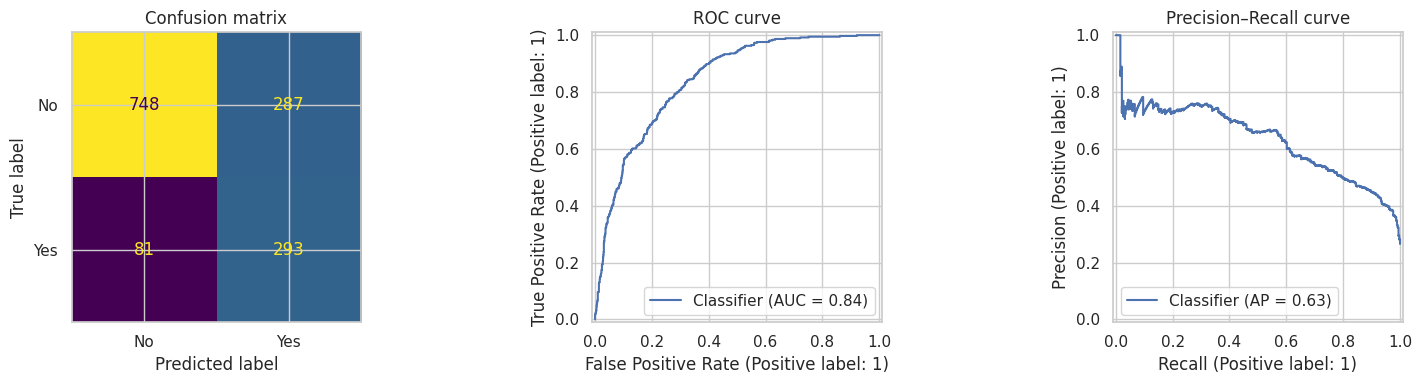

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No", "Yes"], ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix")
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
axes[1].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[2])
axes[2].set_title("Precision–Recall curve")
plt.tight_layout()
plt.show()

## 9. Interpret the model (permutation importance)

Permutation importance is computed on the holdout set for *exploratory interpretation only*. Do not repeatedly change the model based on test-set importance. Feature importance indicates association with predictions, not causation.

,feature,importance_mean,importance_std
4,tenure,0.1577,0.0046
7,InternetService,0.0443,0.0110
17,MonthlyCharges,0.0390,0.0076
14,Contract,0.0367,0.0035
18,TotalCharges,0.0113,0.0022
13,StreamingMovies,0.0048,0.0021
8,OnlineSecurity,0.0042,0.0019
12,StreamingTV,0.0041,0.0025
11,TechSupport,0.0040,0.0011
16,PaymentMethod,0.0034,0.0017


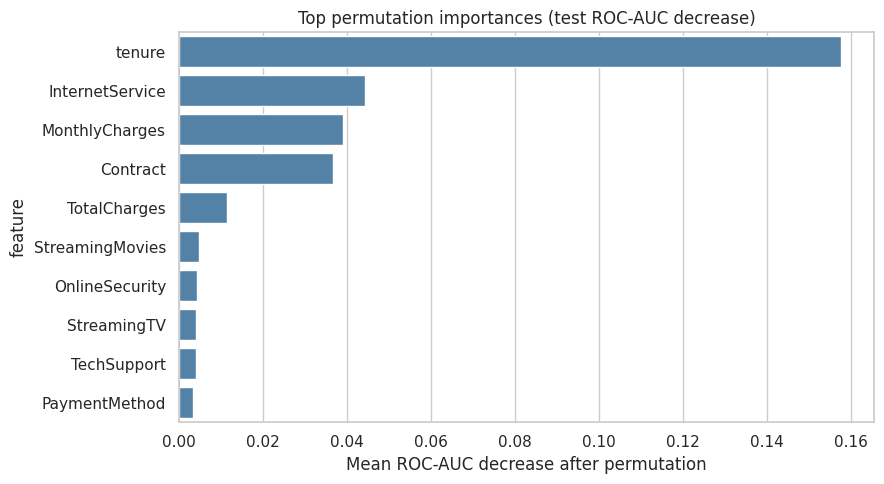

In [16]:
importance = permutation_importance(
    best_pipeline, X_test, y_test, scoring="roc_auc",
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=1
)
feature_importance = (pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": importance.importances_mean,
    "importance_std": importance.importances_std
}).sort_values("importance_mean", ascending=False))
display(feature_importance.head(12).round(4))
plt.figure(figsize=(9, 5))
sns.barplot(data=feature_importance.head(10), x="importance_mean", y="feature", color="steelblue")
plt.title("Top permutation importances (test ROC-AUC decrease)")
plt.xlabel("Mean ROC-AUC decrease after permutation")
plt.tight_layout()
plt.show()

## 10. Save the fitted pipeline

The saved artifact contains the preprocessing steps and trained estimator. Only load `.joblib` files from trusted sources. For production, pin package versions and validate inputs.

In [17]:
output_dir = Path("models")
output_dir.mkdir(parents=True, exist_ok=True)
model_path = output_dir / "customer_churn_pipeline.joblib"
joblib.dump(best_pipeline, model_path)
print("Saved model to:", model_path)

# Example prediction on one held-out customer (features only)
example = X_test.iloc[[0]]
print("Example churn probability:", round(float(best_pipeline.predict_proba(example)[0, 1]), 4))

Saved model to: models/customer_churn_pipeline.joblib
Example churn probability: 0.119


## 11. Conclusions and next steps

Logistic Regression was selected using five-fold cross-validation, with mean ROC-AUC **0.846** (standard deviation **0.013**). On the held-out test set, ROC-AUC was **0.8418** and average precision was **0.6334**. At the baseline threshold of **0.50**, churn recall was **0.78**, precision **0.51**, and F1-score **0.61**.

The model detects many customers who churn, but the moderate precision means retention outreach would also reach customers who may stay. In a real retention program, I would choose the classification threshold on validation data using an explicit outreach budget and intervention cost, then report performance once on a separate test set.

**Observed data patterns:** month-to-month contracts had the highest churn rate (**42.71%**), followed by one-year (**11.27%**) and two-year (**2.83%**) contracts. The permutation-importance analysis ranked tenure highest, followed by internet service, monthly charges and contract type. These are predictive associations, not causal explanations.

**Limitations:** this is a public demonstration dataset; the evaluation does not establish performance on new populations or measure the effectiveness of any retention action.